In [37]:

from collections import Counter
from pathlib import Path
import pickle
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import TwoSlopeNorm

ROOT = Path.cwd()
DATA_ROOT = ROOT / "runs" / "REWARD_DRIVEN_1000"

FIG_DIR = ROOT / "paper_figures" / "unit_activity"
FIG_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = (0.2, 0.3)
SEED = 0
N_NODES = 127

Z_UNITS = [0, 2, 8, 13]
H_UNITS = [4, 22, 37, 57]


def get_run_dir(p, seed):
    return (
        DATA_ROOT
        / f"REWARD_DRIVEN_1000_runs_slurm_20_window_agent_rew_p_{p}"
        / str(seed)
    )


def list_bout_paths(run_dir):
    files = []

    for path in run_dir.glob("bout_*_metrics.npz"):
        match = re.fullmatch(r"bout_(\d+)_metrics\.npz", path.name)
        if match:
            files.append((int(match.group(1)), path))

    if not files:
        raise FileNotFoundError(run_dir)

    return sorted(files)


def select_bouts(p, seed=SEED):
    files = list_bout_paths(get_run_dir(p, seed))
    start = int(round(WINDOW[0] * len(files)))
    end = int(round(WINDOW[1] * len(files)))
    return files[start:end]


In [38]:

def compute_node_points(content_path):
    node_points = {}

    with open(content_path, "rb") as f:
        content = pickle.load(f)

    for ke_bout, no_bout in zip(content.ke, content.no):
        ke = np.asarray(ke_bout)
        no = np.asarray(no_bout)

        if ke.size == 0 or no.size == 0:
            continue

        T = ke.shape[0]
        nodes = np.full(T, np.nan)

        for i, (node, start) in enumerate(no):
            start = int(start)
            end = int(no[i + 1, 1]) if i + 1 < len(no) else T
            start = max(0, min(start, T))
            end = max(start, min(end, T))
            nodes[start:end] = int(node)

        valid = np.isfinite(nodes)

        for (x, y), node in zip(ke[valid, :2], nodes[valid].astype(int)):
            d = node_points.setdefault(
                node, {"x": [], "y": [], "count": 0}
            )
            d["x"].append(float(x))
            d["y"].append(float(y))
            d["count"] += 1

    return node_points


node_points = compute_node_points(ROOT / "outdata" / "A1a-tf")

rng = np.random.default_rng(42)
MAX_POINTS_PER_NODE = 150

xy_parts = []
node_id_parts = []

for node, points in sorted(node_points.items()):
    if not 0 <= node < N_NODES:
        continue

    xs = np.asarray(points["x"])
    ys = np.asarray(points["y"])

    n = min(len(xs), MAX_POINTS_PER_NODE)
    idx = rng.choice(len(xs), size=n, replace=False)

    xy_parts.append(np.column_stack([xs[idx], ys[idx]]))
    node_id_parts.append(np.full(n, node))

xy = np.concatenate(xy_parts)
node_ids = np.concatenate(node_id_parts)

print("Maze nodes:", len(np.unique(node_ids)))


Maze nodes: 127


In [39]:

def load_unit_activity_per_node(files, latent_key):
    node_sum = None
    counts = np.zeros(N_NODES, dtype=int)

    for _, path in files:
        with np.load(path, allow_pickle=False) as data:
            obs = np.asarray(data["obs_full"], dtype=int)
            activity = np.asarray(data[latent_key], dtype=float)

        if activity.ndim == 3 and activity.shape[0] == 1:
            activity = activity[0]

        if activity.ndim != 2:
            raise ValueError(f"Invalid activity shape: {path}")

        # Prior activity predicts the destination; h represents the source.
        nodes = obs[:-1] if latent_key == "h_list" else obs[1:]

        if len(nodes) != len(activity):
            raise ValueError(f"Activity alignment mismatch: {path}")

        if node_sum is None:
            node_sum = np.zeros((N_NODES, activity.shape[1]))

        np.add.at(node_sum, nodes, activity)
        np.add.at(counts, nodes, 1)

    means = np.full_like(node_sum, np.nan, dtype=float)
    visited = counts > 0
    means[visited] = node_sum[visited] / counts[visited, None]

    return means, counts


z_node_mean, _ = load_unit_activity_per_node(
    select_bouts(p=0.0), "z_p"
)

h_node_mean, _ = load_unit_activity_per_node(
    select_bouts(p=0.02), "h_list"
)


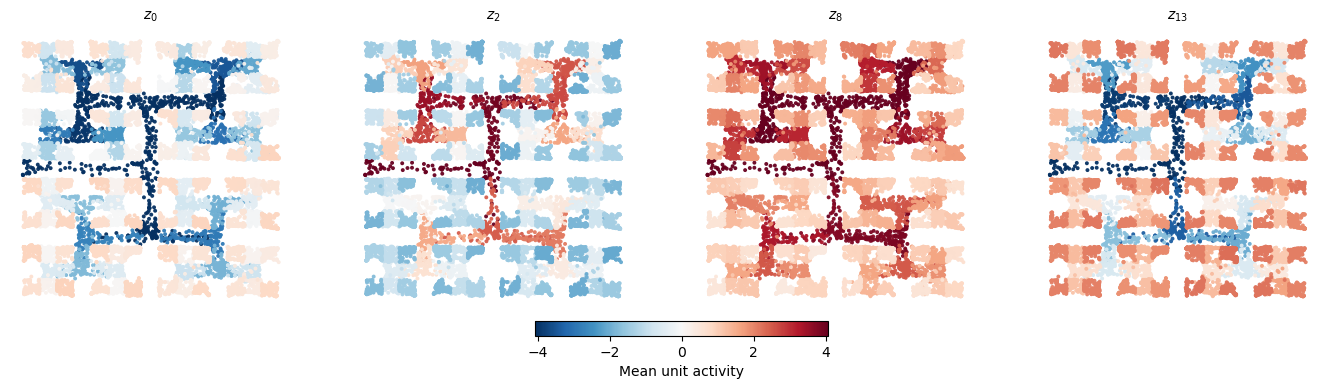

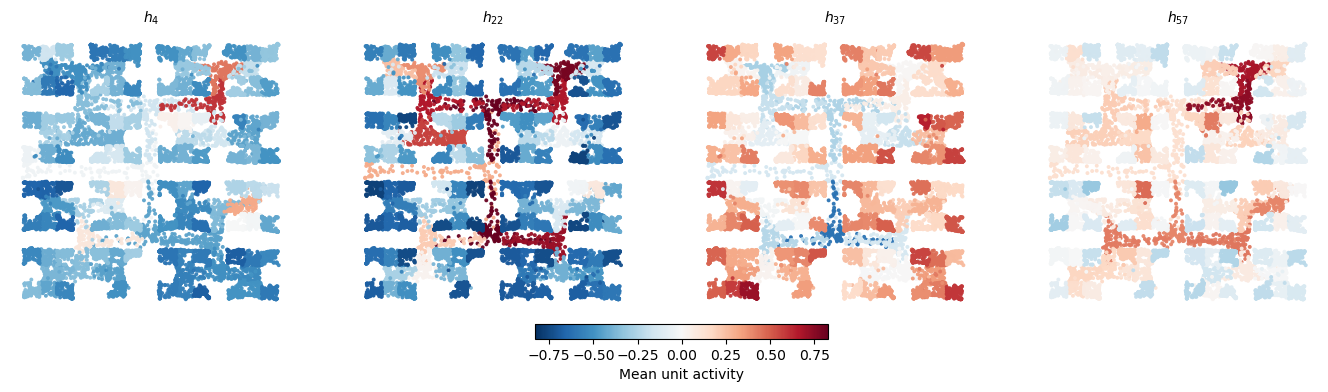

In [40]:

def plot_spatial_units(node_mean, units, label, filename):
    values = node_mean[node_ids, :]
    values = values[np.isfinite(values)]

    vmax = max(np.percentile(np.abs(values), 98), 1e-8)
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)

    fig, axes = plt.subplots(
        1, len(units),
        figsize=(3.5 * len(units), 3.8),
        sharex=True,
        sharey=True
    )

    for ax, unit in zip(np.atleast_1d(axes), units):
        ax.scatter(
            xy[:, 0],
            xy[:, 1],
            c=node_mean[node_ids, unit],
            cmap="RdBu_r",
            norm=norm,
            s=8,
            alpha=0.95,
            linewidths=0,
            rasterized=True
        )

        ax.set_title(rf"${label}_{{{unit}}}$", fontsize=10)
        ax.set_aspect("equal", adjustable="box")
        ax.set_axis_off()

    axes[0].invert_yaxis()

    sm = ScalarMappable(norm=norm, cmap="RdBu_r")
    sm.set_array([])

    cbar = fig.colorbar(
        sm, ax=axes, orientation="horizontal",
        shrink=0.5, pad=0.05, fraction=0.05
    )
    cbar.set_label("Mean unit activity", fontsize=10)

    fig.subplots_adjust(
        left=0.02, right=0.98,
        top=0.92, bottom=0.18,
        wspace=0.08
    )

    fig.savefig(FIG_DIR / f"{filename}.svg", bbox_inches="tight")
    plt.show()
    plt.close(fig)


plot_spatial_units(
    z_node_mean, Z_UNITS, "z",
    "selected_z_units_p0"
)

plot_spatial_units(
    h_node_mean, H_UNITS, "h",
    "selected_h_units_p002"
)


In [41]:

SEQUENCE_FILES = select_bouts(p=0.0)


def extract_path_activity(files, path_nodes, latent_key):
    path_nodes = np.asarray(path_nodes, dtype=int)
    length = len(path_nodes)
    segments = []

    for _, file in files:
        with np.load(file, allow_pickle=False) as data:
            obs = np.asarray(data["obs_full"], dtype=int)
            activity = np.asarray(data[latent_key], dtype=float)

        if activity.ndim == 3 and activity.shape[0] == 1:
            activity = activity[0]

        if activity.ndim != 2 or len(activity) != len(obs) - 1:
            raise ValueError(f"Invalid activity alignment: {file}")

        for start in range(len(obs) - length + 1):
            if np.array_equal(obs[start:start + length], path_nodes):
                segments.append(activity[start:start + length - 1])

    if not segments:
        raise ValueError(f"Path not found: {path_nodes.tolist()}")

    return np.stack(segments)


def zscore_rows(X, eps=1e-8):
    X = np.asarray(X, dtype=float)

    mean = X.mean(axis=1, keepdims=True)
    std = X.std(axis=1, keepdims=True)
    constant = (std < eps).ravel()

    Z = (X - mean) / np.where(std < eps, 1.0, std)
    Z[constant] = 0.0

    return Z


def sorted_path_activity(files, path, latent_key):
    segments = extract_path_activity(files, path, latent_key)
    activity = zscore_rows(segments.mean(axis=0).T)

    peak_steps = (
        activity.shape[1] - 1
        - np.argmax(activity[:, ::-1], axis=1)
    )

    peak_values = activity[
        np.arange(len(activity)), peak_steps
    ]

    order = np.lexsort((peak_values, peak_steps))

    return {
        "activity": activity[order],
        "unit_order": order,
        "path": list(path),
        "n_segments": len(segments),
    }


def plot_sequence(result, label, filename, figsize):
    activity = result["activity"]
    order = result["unit_order"]
    path = result["path"]

    fig, ax = plt.subplots(figsize=figsize)

    im = ax.imshow(
        activity,
        aspect="auto",
        cmap="RdBu_r",
        interpolation="nearest",
        origin="upper"
    )

    transitions = [
        f"{u}→{v}" for u, v in zip(path[:-1], path[1:])
    ]

    ax.set_xticks(np.arange(len(transitions)))
    ax.set_xticklabels(
        transitions, rotation=65, ha="right", fontsize=8
    )

    ax.set_yticks(np.arange(len(order)))
    ax.set_yticklabels(
        [rf"${label}_{{{u}}}$" for u in order],
        fontsize=8 if label == "z" else 6
    )

    ax.set_title(
        f"{path[0]} → ... → {path[-1]}\n"
        f"n = {result['n_segments']} segments",
        fontsize=10
    )

    ax.set_xlabel("Trajectory transition")
    ax.tick_params(length=0)

    cbar = fig.colorbar(
        im, ax=ax, orientation="horizontal",
        fraction=0.05, pad=0.20
    )
    cbar.set_label("Row-normalized activity")

    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{filename}.svg", bbox_inches="tight")

    plt.show()
    plt.close(fig)


Selected path: (1, 4, 9, 19, 40)


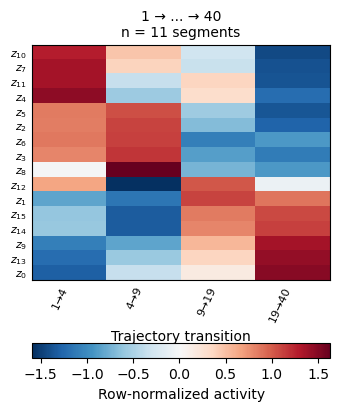

In [42]:

PATH_LENGTH = 5
START_NODES = [1, 2]


def generate_outward_paths(start_node, length):
    paths = [[start_node]]

    for _ in range(length - 1):
        paths = [
            path + [child]
            for path in paths
            for child in (2 * path[-1] + 1, 2 * path[-1] + 2)
            if child < N_NODES
        ]

    return paths


candidate_paths = [
    path
    for start in START_NODES
    for path in generate_outward_paths(start, PATH_LENGTH)
]

candidates = set(map(tuple, candidate_paths))
counts = Counter()

for _, file in SEQUENCE_FILES:
    with np.load(file, allow_pickle=False) as data:
        obs = np.asarray(data["obs_full"], dtype=int)

    for i in range(len(obs) - PATH_LENGTH + 1):
        path = tuple(obs[i:i + PATH_LENGTH])
        if path in candidates:
            counts[path] += 1

path_df = pd.DataFrame([
    {"nodes": tuple(path), "n_segments": counts[tuple(path)]}
    for path in candidate_paths
]).sort_values("n_segments", ascending=False).reset_index(drop=True)

selected_path = path_df.iloc[1]["nodes"]

z_sequence = sorted_path_activity(
    SEQUENCE_FILES, selected_path, "z_p"
)

print("Selected path:", selected_path)

plot_sequence(
    z_sequence,
    label="z",
    filename="prior_sequence",
    figsize=(3.5, 4.2)
)


Selected path: (37, 75, 37, 18, 38, 78, 38, 18)


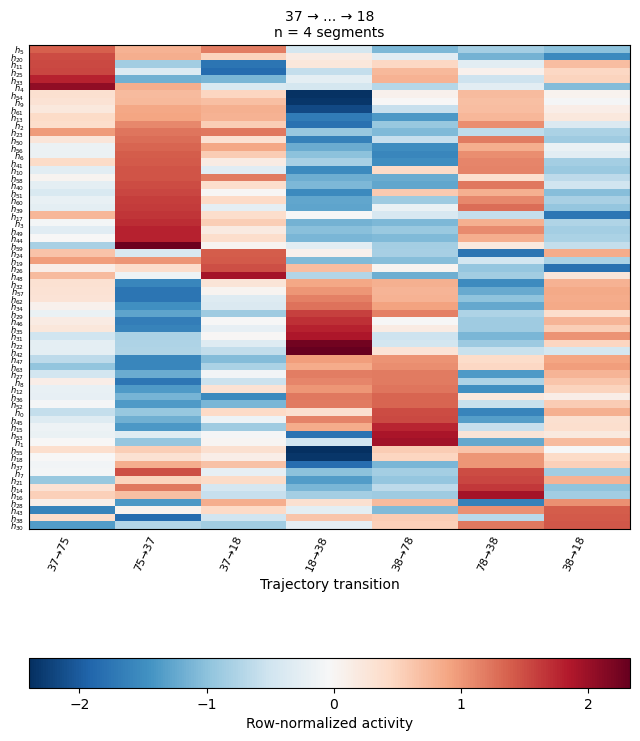

In [43]:

PATH_LENGTH = 8
counts = Counter()
bout_counts = Counter()

for _, file in SEQUENCE_FILES:
    with np.load(file, allow_pickle=False) as data:
        obs = np.asarray(data["obs_full"], dtype=int)

    found = set()

    for i in range(len(obs) - PATH_LENGTH + 1):
        path = tuple(obs[i:i + PATH_LENGTH])
        counts[path] += 1
        found.add(path)

    for path in found:
        bout_counts[path] += 1

path_df = pd.DataFrame([
    {
        "nodes": path,
        "n_segments": count,
        "n_bouts": bout_counts[path],
    }
    for path, count in counts.items()
]).sort_values(
    ["n_segments", "n_bouts"],
    ascending=False
).reset_index(drop=True)

selected_path = path_df.iloc[4]["nodes"]

h_sequence = sorted_path_activity(
    SEQUENCE_FILES, selected_path, "h_list"
)

print("Selected path:", selected_path)

plot_sequence(
    h_sequence,
    label="h",
    filename="recurrent_sequence",
    figsize=(6.5, 7.5)
)
